# PUSL 3205 – Large Language Models and Generative AI
## Lab Sheet 01: Sentiment Analysis Using Traditional Machine Learning

**Objective:** Practice basic NLP tasks.
**Topic:** Text Preprocessing, TF-IDF and Machine Learning
**Libraries:** Pandas, NumPy, NLTK-style preprocessing, Scikit-learn, Matplotlib, Seaborn
**Dataset:** UCI *Sentiment Labelled Sentences* (Amazon + IMDb + Yelp, 3000 sentences)

---

### The big picture
Sentiment analysis means teaching a computer to decide whether a piece of text is **positive** or **negative**.
A computer cannot read words, so the whole lab is about turning text into numbers and finding patterns in them.

```
Raw text → Clean → Explore → Split → Vectorise (BOW) → Train → Evaluate → Predict new text
  Task 1     2        3        4          5               6        7            8
```

In [4]:
# Install / import everything we need
import re
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

nltk.download("stopwords")
sns.set_style("whitegrid")
print("All libraries loaded ")

All libraries loaded 


[nltk_data] Downloading package stopwords to C:\Users\ISIWARA
[nltk_data]     KUMARAGE\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
ZIP_PATH = "sentiment.zip"

# Download and unzip (skip if you already uploaded the zip manually)
urllib.request.urlretrieve(URL, ZIP_PATH)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("data")
    print(z.namelist())

['sentiment labelled sentences/', 'sentiment labelled sentences/.DS_Store', '__MACOSX/', '__MACOSX/sentiment labelled sentences/', '__MACOSX/sentiment labelled sentences/._.DS_Store', 'sentiment labelled sentences/amazon_cells_labelled.txt', 'sentiment labelled sentences/imdb_labelled.txt', '__MACOSX/sentiment labelled sentences/._imdb_labelled.txt', 'sentiment labelled sentences/readme.txt', '__MACOSX/sentiment labelled sentences/._readme.txt', 'sentiment labelled sentences/yelp_labelled.txt', '__MACOSX/._sentiment labelled sentences']


In [7]:
import glob, os

files = {
    "amazon": "amazon_cells_labelled.txt",
    "imdb":   "imdb_labelled.txt",
    "yelp":   "yelp_labelled.txt",
}

frames = []
for source, name in files.items():
    path = glob.glob(f"data/**/{name}", recursive=True)[0]   # find the file wherever it was extracted
    part = pd.read_csv(path, sep="\t", header=None, names=["text", "label"])
    part["source"] = source
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
print("Shape:", df.shape)
df.head()

Shape: (2748, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


text      0
label     0
source    0
dtype: int64

label
1    1386
0    1362
Name: count, dtype: int64


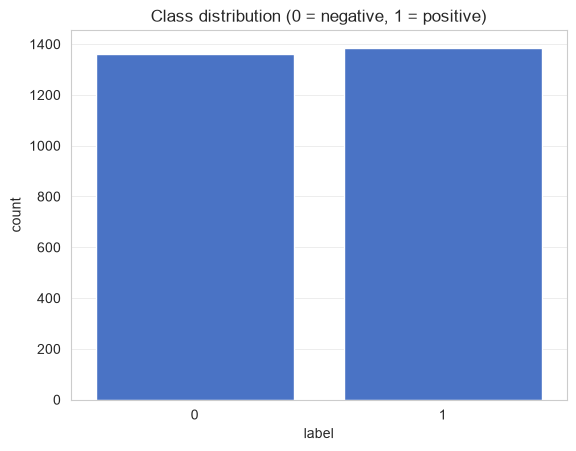

In [8]:
# Quick health check: missing values and class balance
print(df.isnull().sum())
print()
print(df["label"].value_counts())

sns.countplot(x="label", data=df)
plt.title("Class distribution (0 = negative, 1 = positive)")
plt.show()

**What we see:** the data is almost perfectly balanced between positive and negative.
That's good news, because accuracy is a fair metric here and the model won't just favour the bigger class.

## Task 2 – Basic text preprocessing

Raw text is messy. "GREAT!!!" and "great" mean the same thing to us, but not to a computer.
We will:
1. Convert to **lowercase**
2. Remove **punctuation and unnecessary characters** (keep only letters and spaces)
3. Remove **extra whitespace**
4. Save the result in a new **`clean_text`** column
5. **Compare** original vs cleaned text

We write this as one function so we can reuse it later on new sentences (Task 8).

In [9]:
def clean_text(text):
    text = text.lower()                        # 1. lowercase
    text = re.sub(r"[^a-z\s]", " ", text)      # 2. keep only letters and spaces
    text = re.sub(r"\s+", " ", text).strip()   # 3. collapse extra spaces, trim the ends
    return text

# Try it on a messy example
print(clean_text("  WOW!!! This phone's battery is AMAZING... 10/10 :)  "))

wow this phone s battery is amazing


In [10]:
# 4. Create the clean-text column
df["clean_text"] = df["text"].apply(clean_text)

# 5. Compare original and preprocessed text
pd.set_option("display.max_colwidth", 100)
df[["text", "clean_text"]].sample(8, random_state=42)

,text,clean_text
2516,"It's close to my house, it's low-key, non-fancy, affordable prices, good food.",it s close to my house it s low key non fancy affordable prices good food
2642,If you stay in Vegas you must get breakfast here at least once.,if you stay in vegas you must get breakfast here at least once
1359,"Let's start with all the problemsthe acting, especially from the lead professor, was very, very...",let s start with all the problems the acting especially from the lead professor was very very bad
1702,"It's too bad that everyone else involved didn't share Crowe's level of dedication to quality, fo...",it s too bad that everyone else involved didn t share crowe s level of dedication to quality for...
2660,"i felt insulted and disrespected, how could you talk and judge another human being like that?",i felt insulted and disrespected how could you talk and judge another human being like that
564,Yet Plantronincs continues to use the same flawed charger design.,yet plantronincs continues to use the same flawed charger design
1330,Whatever prompted such a documentary is beyond me!,whatever prompted such a documentary is beyond me
2375,Any grandmother can make a roasted chicken better than this one.,any grandmother can make a roasted chicken better than this one


In [11]:
# Remove any rows that became empty after cleaning (rare, but safe)
before = len(df)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print(f"Removed {before - len(df)} empty rows. Rows left: {len(df)}")

Removed 2 empty rows. Rows left: 2746


**What changed:** everything is now lowercase, punctuation, digits and emojis are gone,
and spacing is tidy. Note that we removed digits too. Tokens like "10/10" carry some sentiment, but this keeps the vocabulary simple for a first lab.

## Task 3 – Explore the text data

Before modelling, always look at your data. We will:
- Print some positive and negative examples
- Find the most frequent words
- Compare positive vs negative reviews

In [12]:
print("🟢 POSITIVE examples")
for s in df[df["label"] == 1]["text"].sample(5, random_state=1):
    print(" •", s)

print("\n🔴 NEGATIVE examples")
for s in df[df["label"] == 0]["text"].sample(5, random_state=1):
    print(" •", s)

🟢 POSITIVE examples
 • Battery is holding up well.
 • See it.  
 •  With great sound effects, and impressive special effects, I can't recommend this movie enough.  	1
Call me a nut, but I think this is one of the best movies ever.  	1
Great character actors Telly Savalas and Peter Boyle.  	1
1 hour 54 minutes of sheer tedium, melodrama and horrible acting, a mess of a script, and a sinking feeling of GOOD LORD, WHAT WERE THEY THINKING?  	0
Lots of holes in the script.  	0
It's like a bad two hour TV movie.  	0
Now imagine that every single one of those decisions was made wrong.  	0
The dialogue is atrocious.  	0
The acting is beyond abysmal.  	0
Everything stinks.  	0
Trouble is, the writing and directing make it impossible to establish those things that make a movie watchable, like character, story, theme and so on.  	0
Worse, there's an incredibly weak sub-plot thrown in that follows a little band of latter-day Mansonites as they go after a reporter who's working on a story on the an

        count       mean        std  min   25%   50%   75%     max
label                                                             
0      1362.0  13.772394  43.090386  1.0  6.00  11.0  17.0  1319.0
1      1384.0  12.553468  22.377392  1.0  5.75  10.0  16.0   763.0


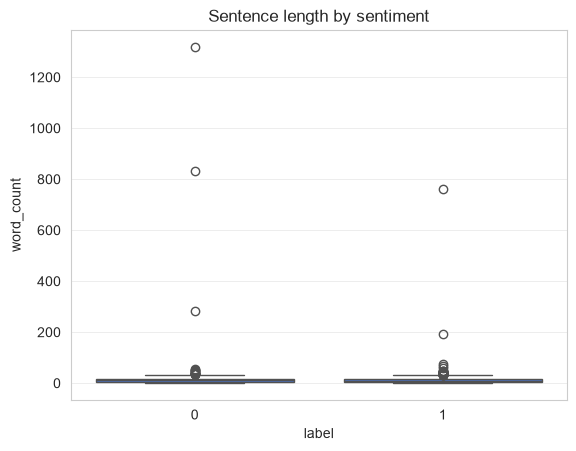

In [13]:
# Sentence length (in words) for each class
df["word_count"] = df["clean_text"].str.split().str.len()

print(df.groupby("label")["word_count"].describe())

sns.boxplot(x="label", y="word_count", data=df)
plt.title("Sentence length by sentiment")
plt.show()

In [14]:
# Most frequent words, with and without stopwords
stop_words = set(stopwords.words("english"))

def top_words(series, n=15, remove_stop=True):
    words = " ".join(series).split()
    if remove_stop:
        words = [w for w in words if w not in stop_words and len(w) > 2]
    return Counter(words).most_common(n)

print("Top words overall (WITH stopwords):")
print(top_words(df["clean_text"], remove_stop=False))

print("\nTop words overall (WITHOUT stopwords):")
print(top_words(df["clean_text"]))

Top words overall (WITH stopwords):
[('the', 1953), ('and', 1138), ('i', 1041), ('a', 891), ('it', 789), ('is', 754), ('to', 670), ('this', 643), ('of', 624), ('was', 571), ('in', 400), ('for', 336), ('that', 316), ('not', 306), ('t', 281)]

Top words overall (WITHOUT stopwords):
[('good', 231), ('great', 210), ('movie', 182), ('phone', 168), ('film', 163), ('one', 146), ('food', 126), ('like', 125), ('place', 114), ('time', 112), ('service', 108), ('bad', 103), ('really', 103), ('well', 92), ('would', 87)]


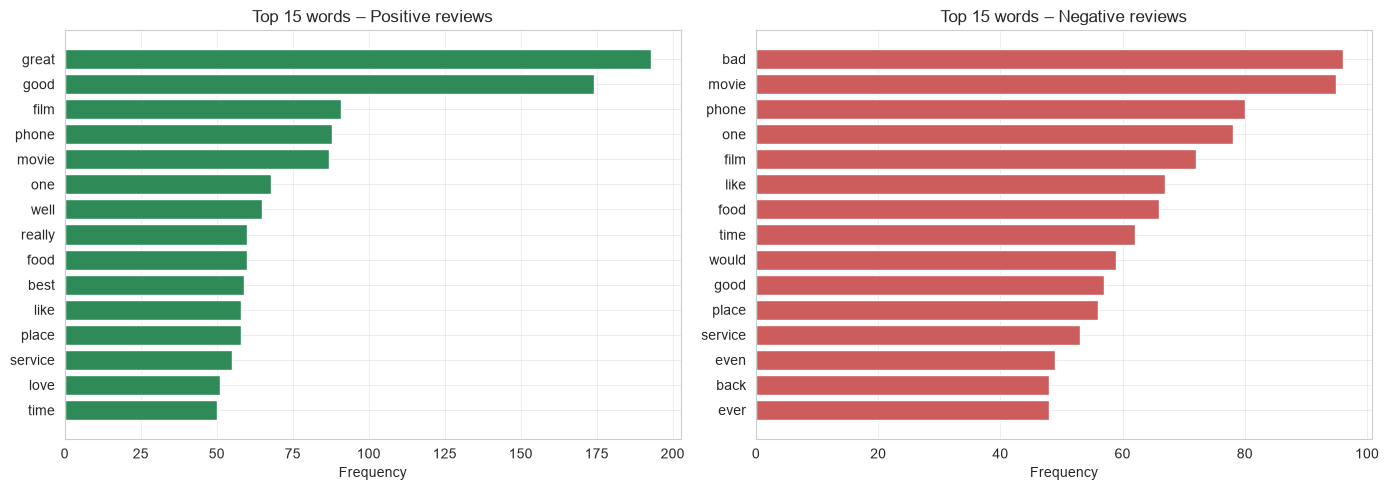

In [16]:
# Compare positive vs negative
pos_top = top_words(df[df["label"] == 1]["clean_text"], 15)
neg_top = top_words(df[df["label"] == 0]["clean_text"], 15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, color in [(axes[0], pos_top, "Positive reviews", "seagreen"),
                               (axes[1], neg_top, "Negative reviews", "indianred")]:
    words, counts = zip(*data)
    ax.barh(words[::-1], counts[::-1], color=color)
    ax.set_title(f"Top 15 words – {title}")
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.show()

#### Task 3 (continued): Observe differences between positive and negative reviews

**Theory:**
A word that is frequent is not necessarily a *useful* word. Looking at your chart, `movie`, `phone` and `film` appear in **both** the positive and negative lists, because they describe the *topic*, not the *feeling*. A word helps a classifier only when it is used **much more in one class than the other**.

To measure this we use the **log-odds ratio**:

$$\text{score}(w) = \ln\frac{P(w \mid \text{positive})}{P(w \mid \text{negative})}$$

* score **> 0** → the word leans positive
* score **< 0** → the word leans negative
* score **≈ 0** → the word is neutral (appears equally in both)

**Explanation:**
* We count each word separately in positive and negative reviews, ignoring stop words.
* **+1 smoothing** avoids dividing by zero for words that appear in only one class.
* We ignore words with fewer than 10 total occurrences, because rare words give unreliable scores.

In [20]:
# Fix column names if needed
df = df.rename(columns={"label": "sentiment", "Label": "sentiment",
                        "text": "review", "clean_text": "clean_review"})

# Define the cleaning function if this notebook doesn't have it yet
import re
if "preprocess_text" not in globals():
    def preprocess_text(text):
        text = text.lower()                          # 1. lowercase
        text = re.sub(r"n't\b", " not", text)        # 2. keep negation: didn't -> did not
        text = re.sub(r"[^a-z\s]", " ", text)        # 3. drop punctuation, digits, symbols
        text = re.sub(r"\s+", " ", text).strip()     # 4. collapse extra whitespace
        return text

# Build clean_review only if it still doesn't exist
if "clean_review" not in df.columns:
    df["clean_review"] = df["review"].apply(preprocess_text)

print("Columns:", df.columns.tolist())

Columns: ['review', 'sentiment', 'source', 'clean_review', 'word_count']


#### Task 3 (continued): Observe differences between positive and negative reviews

**Theory:**
A word that is frequent is not necessarily a *useful* word. In the previous chart, `movie`, `film` and `phone` appeared in **both** the positive and negative lists, because they describe the *topic*, not the *feeling*. A word helps a classifier only when it is used **much more in one class than the other**.

To measure this we use the **log-odds ratio**:

$$\text{score}(w) = \ln\frac{P(w \mid \text{positive})}{P(w \mid \text{negative})}$$

* score **> 0** → the word leans positive
* score **< 0** → the word leans negative
* score **≈ 0** → the word is neutral (appears equally in both)

**Explanation:**
* We count each word separately in positive and negative reviews, ignoring stop words.
* **+1 smoothing** avoids dividing by zero for words that appear in only one class.
* We ignore words with fewer than 10 total occurrences, because rare words give unreliable scores.
* `sort_values` puts the most negative words first and the most positive words last, so we print the two ends of the table.

In [21]:
import numpy as np
from collections import Counter

# Stop words, keeping negations (only defined if you haven't already)
try:
    STOP_WORDS
except NameError:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "neither", "cannot", "cant", "dont", "wont"}
    STOP_WORDS = sorted(set(ENGLISH_STOP_WORDS) - NEGATIONS)

stop_set = set(STOP_WORDS)

def count_words(texts):
    words = " ".join(texts).split()
    return Counter(w for w in words if w not in stop_set and len(w) > 2)

# Count words separately in positive and negative reviews
pos_counts = count_words(df.loc[df["sentiment"] == 1, "clean_review"])
neg_counts = count_words(df.loc[df["sentiment"] == 0, "clean_review"])
pos_total, neg_total = sum(pos_counts.values()), sum(neg_counts.values())

# Log-odds score: > 0 leans positive, < 0 leans negative
rows = []
for w in set(pos_counts) | set(neg_counts):
    p, n = pos_counts[w], neg_counts[w]
    if p + n >= 10:                                    # ignore rare words
        score = np.log(((p + 1) / pos_total) / ((n + 1) / neg_total))
        rows.append((w, p, n, round(score, 3)))

distinct = (pd.DataFrame(rows, columns=["word", "pos_count", "neg_count", "log_odds"])
              .sort_values("log_odds")
              .reset_index(drop=True))

print("Most NEGATIVE-leaning words:")
display(distinct.head(10))

print("Most POSITIVE-leaning words:")
display(distinct.tail(10).iloc[::-1].reset_index(drop=True))

Most NEGATIVE-leaning words:


,word,pos_count,neg_count,log_odds
0,poor,0,27,-3.305
1,worst,1,39,-2.969
2,waste,1,32,-2.776
3,money,1,30,-2.714
4,bland,0,13,-2.612
5,unfortunately,0,12,-2.538
6,disappointing,0,12,-2.538
7,sucked,0,12,-2.538
8,bad,7,96,-2.468
9,disappointment,0,11,-2.458


Most POSITIVE-leaning words:


,word,pos_count,neg_count,log_odds
0,delicious,23,0,3.205
1,fantastic,18,0,2.971
2,interesting,15,0,2.800
3,wonderful,24,1,2.553
4,pleased,10,0,2.425
5,great,193,17,2.405
6,fine,20,1,2.378
7,nice,49,4,2.330
8,works,49,4,2.330
9,awesome,19,1,2.330


In [22]:
print("Rows in distinct table:", len(distinct))
print("Positive word types   :", len(pos_counts))
print("Negative word types   :", len(neg_counts))
print("STOP_WORDS type/size  :", type(STOP_WORDS).__name__, len(STOP_WORDS))
print()
print(distinct.head(10).to_string())

Rows in distinct table: 309
Positive word types   : 2988
Negative word types   : 3033
STOP_WORDS type/size  : list 308

             word  pos_count  neg_count  log_odds
0            poor          0         27    -3.305
1           worst          1         39    -2.969
2           waste          1         32    -2.776
3           money          1         30    -2.714
4           bland          0         13    -2.612
5   unfortunately          0         12    -2.538
6   disappointing          0         12    -2.538
7          sucked          0         12    -2.538
8             bad          7         96    -2.468
9  disappointment          0         11    -2.458


In [23]:
print("Most NEGATIVE-leaning words:")
print(distinct.head(10).to_string(index=False))

print("\nMost POSITIVE-leaning words:")
print(distinct.tail(10).iloc[::-1].to_string(index=False))

Most NEGATIVE-leaning words:
          word  pos_count  neg_count  log_odds
          poor          0         27    -3.305
         worst          1         39    -2.969
         waste          1         32    -2.776
         money          1         30    -2.714
         bland          0         13    -2.612
 unfortunately          0         12    -2.538
 disappointing          0         12    -2.538
        sucked          0         12    -2.538
           bad          7         96    -2.468
disappointment          0         11    -2.458

Most POSITIVE-leaning words:
       word  pos_count  neg_count  log_odds
  delicious         23          0     3.205
  fantastic         18          0     2.971
interesting         15          0     2.800
  wonderful         24          1     2.553
    pleased         10          0     2.425
      great        193         17     2.405
       fine         20          1     2.378
       nice         49          4     2.330
      works         49      

**Observations from the log-odds tables:**

1. **Strongest negative words:** `poor`, `worst`, `waste`, `bland`, `disappointing`, `sucked`, `bad`. Many of these appear in the negative reviews only (for example `poor` appears 27 times in negative reviews and **0** times in positive ones), so their scores are strongly negative.
2. **Strongest positive words:** `delicious`, `fantastic`, `interesting`, `wonderful`, `great`, `awesome`, `nice`. For example `delicious` appears 23 times in positive reviews and **never** in negative ones.
3. **Some words are domain clues:** `money` (as in "waste of money") and `works` (as in "works great") lean negative and positive respectively, even though they are not emotion words on their own. This shows the model learns the *context in which words are used*, not just dictionary sentiment.
4. **`great` is the most frequent positive word** (193 vs 17), but its log-odds is lower than `delicious` (0 negative uses), because the score measures how *one-sided* a word is, not how common it is.
5. **Conclusion:** these one-sided words are exactly what a classifier will weight most heavily. Topic words like `movie` or `phone` score near 0, so they carry almost no sentiment signal.

#### Task 3 (continued): Does review length differ between positive and negative reviews?

**Theory:**
Besides the words themselves, a simple feature we can check is **length**. If negative reviewers wrote much longer (or shorter) sentences than positive ones, length alone would give the model extra information.

**Explanation:**
* **`.str.split().str.len()`** splits each cleaned review into words and counts them.
* **`groupby("sentiment").describe()`** gives count, mean, median (50%) and spread for each class.
* **Histogram with `hue`**: overlays the two length distributions so we can compare their shapes directly.

Review length (words) by sentiment:
            count   mean    std  min   25%   50%   75%     max
sentiment                                                     
0          1362.0  13.77  43.09  1.0  6.00  11.0  17.0  1319.0
1          1384.0  12.55  22.38  1.0  5.75  10.0  16.0   763.0


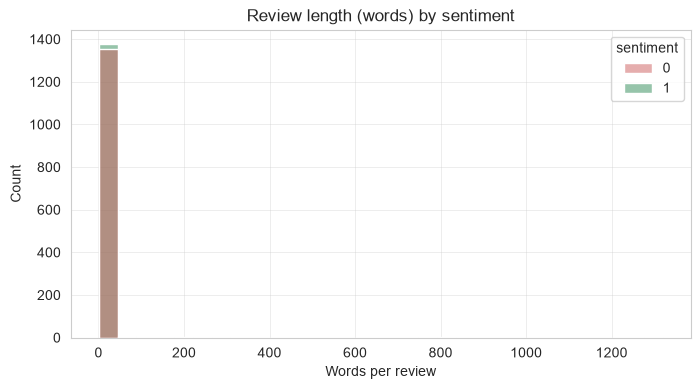

In [24]:
df["word_count"] = df["clean_review"].str.split().str.len()

print("Review length (words) by sentiment:")
print(df.groupby("sentiment")["word_count"].describe().round(2).to_string())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="word_count", hue="sentiment", bins=30,
             palette=["indianred", "seagreen"], multiple="layer", alpha=0.5)
plt.title("Review length (words) by sentiment")
plt.xlabel("Words per review")
plt.show()

In [25]:
import os, glob, csv
import pandas as pd

files = ["amazon_cells_labelled.txt", "imdb_labelled.txt", "yelp_labelled.txt"]

frames = []
for name in files:
    # finds the file wherever it was extracted under your notebook folder
    path = glob.glob(os.path.join("**", name), recursive=True)[0]
    part = pd.read_csv(path, sep="\t", header=None, names=["review", "sentiment"],
                       quoting=csv.QUOTE_NONE, encoding="utf-8")   # <- the important line
    part["source"] = name.split("_")[0]
    frames.append(part)
    print(f"Loaded {name:<28} -> {len(part)} rows")

df = pd.concat(frames, ignore_index=True)
print("\nDataset shape:", df.shape)

Loaded amazon_cells_labelled.txt    -> 1000 rows
Loaded imdb_labelled.txt            -> 1000 rows
Loaded yelp_labelled.txt            -> 1000 rows

Dataset shape: (3000, 3)


In [26]:
# Remove exact duplicates and rebuild the cleaned column
df = df.drop_duplicates(subset="review").reset_index(drop=True)
df["clean_review"] = df["review"].apply(preprocess_text)
df["word_count"] = df["clean_review"].str.split().str.len()

print("Rows:", len(df))
print("Longest review (words):", df["word_count"].max())

Rows: 2983
Longest review (words): 74


### Task 4: Split the Dataset

**Question (from the lab sheet):**
> *4. Split the dataset*

**Theory:**
A model tested on the same data it learned from will look perfect, because it can simply memorise the answers. This is called **overfitting**. To measure real performance, we hide part of the data (the **test set**) and use it only for the final evaluation. The rest (the **training set**) is where the model learns.

**Explanation:**
* **`X` and `y`**: `X` holds the input (the cleaned text) and `y` holds the correct answer (the sentiment label).
* **`test_size=0.2`**: 80% of the data for training and 20% for testing, a standard split.
* **`random_state=42`**: fixes the random shuffle so the split and all later results are reproducible.
* **`stratify=y`**: keeps the positive/negative ratio the same in both sets, so neither set is accidentally lopsided.
* **Split before vectorising (Task 5)**: the vectoriser must learn its vocabulary from the training data *only*. Otherwise information from the test set leaks into training (**data leakage**) and the scores look better than they really are.

In [27]:
from sklearn.model_selection import train_test_split

SEED = 42

X = df["clean_review"]     # input: cleaned text
y = df["sentiment"]        # target: 0 = negative, 1 = positive

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples : {len(X_test)}")
print("\nTrain label proportions:")
print(y_train.value_counts(normalize=True).round(3).to_string())
print("\nTest label proportions:")
print(y_test.value_counts(normalize=True).round(3).to_string())

Training samples: 2386
Testing samples : 597

Train label proportions:
sentiment
0    0.5
1    0.5

Test label proportions:
sentiment
0    0.501
1    0.499


### Task 5: Create BOW Representation

**Question (from the lab sheet):**
> *5. Create BOW representation*

**Theory:**
Machine learning models work with numbers, not words. **Bag of Words (BOW)** converts each sentence into a vector of word counts. The vocabulary is every distinct word found in the training data, and each sentence becomes a row of numbers, one column per vocabulary word. Word **order is ignored**, which is why it is called a "bag" of words.

| sentence | great | food | not | good |
|---|---|---|---|---|
| "great food" | 1 | 1 | 0 | 0 |
| "food not good" | 0 | 1 | 1 | 1 |

The lab topic also mentions **TF-IDF**, a smarter version of BOW. Instead of raw counts it uses

$$\text{tf-idf}(w, d) = \text{tf}(w, d) \times \log\frac{N}{\text{df}(w)}$$

where `tf` is how often word *w* appears in document *d*, *N* is the total number of documents, and `df(w)` is the number of documents containing *w*. Words that appear everywhere get a low weight, and rare, distinctive words get a high one. We compare both later.

**Explanation:**
* **`CountVectorizer`**: builds the vocabulary and the count matrix.
* **`fit_transform(X_train)`** learns the vocabulary *and* converts the training text. **`transform(X_test)`** only converts, using the vocabulary already learned. Words never seen in training are ignored. This is how we avoid **data leakage**.
* **`stop_words=STOP_WORDS`**: removes meaningless words (`the`, `and`, ...) but **keeps negations** such as `not`.
* **`min_df=2`**: ignores words that appear in fewer than 2 sentences. These are mostly typos and one-offs that cause overfitting.
* **Sparse matrix**: almost every cell is 0, because a sentence uses only about 8 of ~2000 vocabulary words. Scikit-learn stores only the non-zero values, which saves a lot of memory.

In [28]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(stop_words=STOP_WORDS, min_df=2)

X_train_bow = bow.fit_transform(X_train)     # learn vocabulary from TRAIN only
X_test_bow  = bow.transform(X_test)          # reuse that vocabulary for TEST

vocab = bow.get_feature_names_out()
sparsity = 100 * (1 - X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1]))

print("Train matrix shape:", X_train_bow.shape, "(sentences x vocabulary words)")
print("Test matrix shape :", X_test_bow.shape)
print("Vocabulary size   :", len(vocab))
print(f"Sparsity          : {sparsity:.2f}% of cells are zero")
print("Sample vocabulary :", list(vocab[:20]))

Train matrix shape: (2386, 1647) (sentences x vocabulary words)
Test matrix shape : (597, 1647)
Vocabulary size   : 1647
Sparsity          : 99.73% of cells are zero
Sample vocabulary : ['ability', 'able', 'absolutely', 'abysmal', 'achievement', 'act', 'acted', 'acting', 'action', 'actor', 'actors', 'actress', 'actresses', 'actually', 'adaptation', 'addition', 'adorable', 'advise', 'aerial', 'afraid']


In [29]:
# See exactly what BOW does to one training sentence
i = 3
print("Sentence :", X_train.iloc[i])
print("Label    :", "Positive" if y_train.iloc[i] == 1 else "Negative")

row = X_train_bow[i].toarray().ravel()
print("\nBOW vector (non-zero entries only):")
print({w: int(c) for w, c in zip(vocab, row) if c > 0})

print("\nTotal numbers in this vector:", len(row))
print("Non-zero numbers            :", int((row > 0).sum()))

Sentence : they do not care about the consumer one bit
Label    : Negative

BOW vector (non-zero entries only):
{'bit': 1, 'care': 1, 'consumer': 1, 'not': 1}

Total numbers in this vector: 1647
Non-zero numbers            : 4


**Observations:**
1. The training matrix has **2386 rows** (sentences) and **1647 columns** (vocabulary words). The test matrix has **597 rows** and the **same 1647 columns**, because it was converted using the vocabulary learned from the training data only.
2. The matrix is **99.73% zeros**. A typical sentence uses only a handful of the 1647 words, so each row is mostly empty. Scikit-learn stores it as a *sparse matrix* to save memory.
3. The sample vocabulary is alphabetical and contains real words (`able`, `acting`, `adorable`). Rare words that appear in fewer than 2 sentences were removed (`min_df=2`), and so were stop words like `the`.
4. **Worked example:** the sentence *"they do not care about the consumer one bit"* (a negative review) becomes only 4 non-zero numbers out of 1647: `bit`, `care`, `consumer` and `not`, each counted once. The stop words `they`, `do`, `about`, `the` and `one` were dropped, but **`not` was kept** because we protected negations. This matters: without `not`, the sentence would read "care consumer bit", which looks positive.
5. **Limitation:** BOW ignores word order. "Not good" and "good, not" give exactly the same vector, which is why sarcasm and complex negation will cause mistakes later.

### Task 6: Train a ML Model

**Question (from the lab sheet):**
> *6. Train a ML model (SVM, Logistic Regression etc...)*

**Theory:**
Training means letting an algorithm look at many labelled examples (BOW vectors with known sentiment) and adjust itself until it makes as few mistakes as possible. We train three classic models and compare them.

* **Logistic Regression** gives each word a weight *w*. For a sentence it computes a score $z = w_1x_1 + w_2x_2 + \dots + b$ and squashes it into a probability with the sigmoid function:

$$P(\text{positive}) = \frac{1}{1 + e^{-z}}$$

  Positive weights push towards "positive" and negative weights towards "negative". It is fast and **interpretable**, because we can read the weights directly.

* **Support Vector Machine (SVM)** finds the dividing boundary with the **widest margin** between the two classes. `LinearSVC` is the linear version, and it works very well on high-dimensional sparse data like text.

* **Naive Bayes** is a probabilistic baseline. It estimates how likely each word is in positive vs negative reviews and combines them, "naively" assuming words are independent. It is extremely fast and often strong on small text datasets.

**Explanation:**
* We train **three models on the same BOW features**, so the comparison is fair.
* **`.fit(X_train_bow, y_train)`** is the learning step: the model adjusts its weights to minimise mistakes on the training set.
* **`max_iter=1000`** gives Logistic Regression enough iterations to converge.
* **`random_state=SEED`** makes the results reproducible.
* The test set is **not used** here. It is kept for Task 7.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Linear SVM":          LinearSVC(random_state=SEED),
    "Naive Bayes":         MultinomialNB(),
}

for name, model in models.items():
    model.fit(X_train_bow, y_train)                       # learn from TRAIN only
    train_acc = model.score(X_train_bow, y_train)         # accuracy on data it has seen
    print(f"{name:<20} trained ✅   training accuracy = {train_acc:.3f}")

Logistic Regression  trained ✅   training accuracy = 0.950
Linear SVM           trained ✅   training accuracy = 0.983
Naive Bayes          trained ✅   training accuracy = 0.917


**Observation:** All three models trained successfully. Their accuracy on the **training data** is 0.950 (Logistic Regression), 0.983 (Linear SVM) and 0.917 (Naive Bayes). These numbers are **not** the real performance, because the models are being scored on sentences they have already seen. The SVM's 98% in particular suggests it has nearly memorised the training set. The true test comes in Task 7, where we use the 597 unseen sentences.

### Task 7: Evaluate the Model's Performance

**Question (from the lab sheet):**
> *7. Evaluate the model's performance. (Accuracy, Precision, Recall, F1)*

**Theory:**
We now test each model on the **unseen test set**. Every prediction falls into one of four boxes (the **confusion matrix**), taking "positive" as the target class:

| | Predicted positive | Predicted negative |
|---|---|---|
| **Actually positive** | TP (true positive) | FN (false negative) |
| **Actually negative** | FP (false positive) | TN (true negative) |

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}\qquad F1=\frac{2\cdot P\cdot R}{P+R}$$

* **Accuracy**: the overall percentage of correct predictions.
* **Precision**: when the model says "positive", how often is it right? Low precision means many false alarms.
* **Recall**: of all genuinely positive sentences, how many did the model find? Low recall means many misses.
* **F1-score**: the harmonic mean of precision and recall. It is high only when *both* are high.

**Explanation:**
* **`model.predict(X_test_bow)`** produces a predicted label for each of the 597 test sentences.
* We compute the four metrics for every model and put them in **one comparison table**.
* All metrics use the true labels `y_test`, which the model never saw during training.

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(name, y_true, y_pred):
    return {"Model": name,
            "Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall":    recall_score(y_true, y_pred),
            "F1-score":  f1_score(y_true, y_pred)}

# Predict on the UNSEEN test set
predictions = {name: m.predict(X_test_bow) for name, m in models.items()}

results = pd.DataFrame([evaluate(n, y_test, p) for n, p in predictions.items()]).set_index("Model").round(4)

print("Test-set performance:")
print(results.to_string())
print("\nBest model by F1:", results["F1-score"].idxmax())

Test-set performance:
                     Accuracy  Precision  Recall  F1-score
Model                                                     
Logistic Regression    0.8090     0.8239  0.7852    0.8041
Linear SVM             0.7923     0.8063  0.7685    0.7869
Naive Bayes            0.8208     0.8328  0.8020    0.8171

Best model by F1: Naive Bayes


**Interpretation of the test results:**

| Model | Training accuracy | Test accuracy | Gap |
|---|---|---|---|
| Logistic Regression | 0.950 | 0.809 | 14.1 pts |
| Linear SVM | 0.983 | 0.792 | 19.1 pts |
| Naive Bayes | 0.917 | 0.821 | 9.6 pts |

1. **Naive Bayes is the best model** on the test set (F1 = 0.817), followed by Logistic Regression (0.804) and Linear SVM (0.787). The differences are small, about 3 percentage points, so on a dataset this size they are all reasonably comparable.
2. **Overfitting is visible.** Every model scores much lower on unseen data than on the training data. The SVM has the biggest gap (98.3% → 79.2%), meaning it memorised the training sentences most. Naive Bayes has the smallest gap, which is why it generalises best here. Simple, strongly-regularised models often win on small text datasets.
3. **Precision is higher than recall for all models** (for example 0.833 vs 0.802 for Naive Bayes). When a model says "positive" it is usually right, but it misses some genuinely positive reviews and labels them negative.
4. **Baseline context:** the classes are balanced (50/50), so random guessing would give about 50%. Scoring 79–82% with only word counts is a solid baseline, but it also shows the ceiling of BOW: word order, sarcasm and context are not captured.

In [32]:
from sklearn.metrics import classification_report

for name, pred in predictions.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Negative", "Positive"]))

=== Logistic Regression ===
              precision    recall  f1-score   support

    Negative       0.80      0.83      0.81       299
    Positive       0.82      0.79      0.80       298

    accuracy                           0.81       597
   macro avg       0.81      0.81      0.81       597
weighted avg       0.81      0.81      0.81       597

=== Linear SVM ===
              precision    recall  f1-score   support

    Negative       0.78      0.82      0.80       299
    Positive       0.81      0.77      0.79       298

    accuracy                           0.79       597
   macro avg       0.79      0.79      0.79       597
weighted avg       0.79      0.79      0.79       597

=== Naive Bayes ===
              precision    recall  f1-score   support

    Negative       0.81      0.84      0.82       299
    Positive       0.83      0.80      0.82       298

    accuracy                           0.82       597
   macro avg       0.82      0.82      0.82       597
weighte

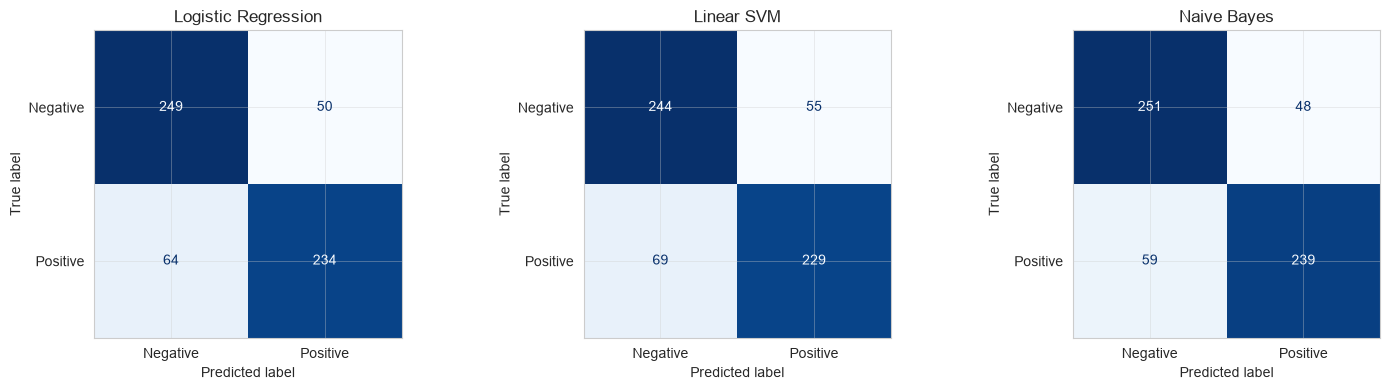

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Negative", "Positive"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Observations from the confusion matrices** (rows = actual, columns = predicted; the test set has 299 negative and 298 positive sentences):

| Model | TN | FP | FN | TP |
|---|---|---|---|---|
| Logistic Regression | 249 | 50 | 64 | 234 |
| Linear SVM | 244 | 55 | 69 | 229 |
| Naive Bayes | 251 | 48 | 59 | 239 |

1. **The diagonal (TN and TP) holds the correct predictions.** Naive Bayes gets the most right: 251 + 239 = 490 of 597 (82.1%), matching its accuracy of 0.8208.
2. **False negatives (FN) outnumber false positives (FP) for every model.** For example, Naive Bayes wrongly labels 59 positive reviews as negative, but only 48 negative reviews as positive. This is why **recall (0.802) is lower than precision (0.833)**.
3. **Likely cause of the errors:** positive reviews that include negative-sounding words ("not bad", "I was worried it would be terrible, but it was great") or are phrased in a subtle way. BOW has no way to understand this context.
4. **Both classes are similarly hard.** The errors are spread fairly evenly (48 to 69 per type), so the models are not biased towards one class. This fits the balanced dataset.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# 5-fold cross-validation on the TRAINING data.
# The pipeline re-learns the vocabulary inside each fold, so there is no data leakage.
print(f"{'Model':<20} {'Mean F1':>8} {'Std':>7}")
print("-" * 38)
for name, model in models.items():
    pipe = Pipeline([
        ("bow", CountVectorizer(stop_words=STOP_WORDS, min_df=2)),
        ("clf", model),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1")
    print(f"{name:<20} {scores.mean():>8.3f} {scores.std():>7.3f}")

Model                 Mean F1     Std
--------------------------------------
Logistic Regression     0.815   0.009
Linear SVM              0.801   0.007
Naive Bayes             0.818   0.015


#### Cross-validation: how stable are these results?

**Theory:**
A single train/test split can be lucky or unlucky: a different random split might give slightly different scores. **K-fold cross-validation** fixes this by splitting the training data into 5 parts (folds). It trains on 4 folds, tests on the 5th, and repeats 5 times so every fold is used once as the test set. We then report the **mean** and **standard deviation (std)** of the 5 scores.

**Explanation:**
* **`Pipeline`** chains the vectoriser and the classifier, so the vocabulary is re-learned inside each fold. This prevents data leakage.
* **`scoring="f1"`** uses the F1-score as the measure.
* **A small std** means the model's performance is stable. A large std means it depends heavily on which sentences it was trained on.

**Observations from cross-validation:**

| Model | CV mean F1 | CV std | Test F1 (earlier) |
|---|---|---|---|
| Logistic Regression | 0.815 | 0.009 | 0.804 |
| Linear SVM | 0.801 | 0.007 | 0.787 |
| Naive Bayes | 0.818 | 0.015 | 0.817 |

1. **The results are consistent.** The cross-validation scores (0.80 to 0.82) are close to the test-set scores from the single split. This confirms our test results were not a lucky split.
2. **The standard deviations are small** (0.007 to 0.015), so all three models are stable across different data subsets.
3. **Naive Bayes and Logistic Regression are effectively tied.** Their means (0.818 vs 0.815) differ by far less than one standard deviation, so we cannot claim one is truly better. Naive Bayes has the highest mean but also the highest variation (0.015).
4. **Linear SVM is consistently the weakest by about 1.5 points.** Combined with its 98% training accuracy, this points to overfitting: it fits the training data too tightly.
5. **Conclusion:** for this dataset and BOW features, the three models perform within a few points of each other. The features, not the choice of algorithm, are the main limit.

#### Which words drive the model's decisions?

**Theory:**
Logistic Regression learns one **weight** per vocabulary word. A large **positive** weight means the word pushes the prediction towards *positive*, and a large **negative** weight pushes it towards *negative*. Looking at the weights lets us check that the model learned sensible sentiment patterns rather than noise. This **interpretability** is a major advantage of linear models.

**Explanation:**
* **`lr.coef_[0]`** holds the weights, one per word in `vocab`.
* We sort them and take the 12 lowest (most negative) and 12 highest (most positive).
* The bar chart colours negative-weight words red and positive-weight words green.

Most NEGATIVE words (weight):
bad              -2.311
poor             -2.110
worst            -2.068
terrible         -1.963
not              -1.903
disappointment   -1.827
avoid            -1.606
disappointing    -1.546
slow             -1.540
stupid           -1.509
awful            -1.505
average          -1.496

Most POSITIVE words (weight):
great        2.769
love         2.079
nice         2.015
delicious    1.995
excellent    1.864
happier      1.855
wonderful    1.824
awesome      1.758
loved        1.666
works        1.665
happy        1.631
amazing      1.627


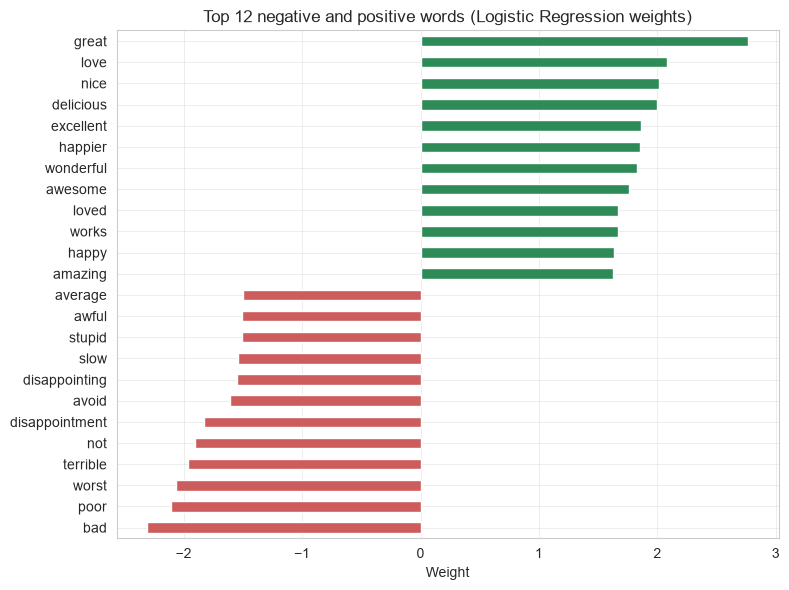

In [35]:
# Which words does Logistic Regression rely on most?
lr = models["Logistic Regression"]
weights = pd.Series(lr.coef_[0], index=vocab).sort_values()

top_neg = weights.head(12)
top_pos = weights.tail(12)

print("Most NEGATIVE words (weight):")
print(top_neg.round(3).to_string())
print("\nMost POSITIVE words (weight):")
print(top_pos.iloc[::-1].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
pd.concat([top_neg, top_pos]).plot.barh(
    color=["indianred"] * 12 + ["seagreen"] * 12, ax=ax)
ax.set_title("Top 12 negative and positive words (Logistic Regression weights)")
ax.set_xlabel("Weight")
plt.tight_layout()
plt.show()

**Observations from the word weights:**

1. **The model learned sensible sentiment words.** The strongest positive weights go to `great` (+2.77), `love`, `nice`, `delicious`, `excellent` and `wonderful`. The strongest negative weights go to `bad` (-2.31), `poor`, `worst`, `terrible`, `disappointment` and `awful`. This is a useful sanity check that the model is learning real signal and not noise.
2. **`not` is one of the strongest negative words (-1.90).** Our decision to keep negations in the stop-word list paid off: if `not` had been removed, the model would have lost one of its most useful clues. Phrases like "not good" and "not recommend" are strongly negative.
3. **Some words are domain-specific rather than emotional.** `works` (+1.67) comes from product reviews ("works great"), `slow` (-1.54) from restaurant and phone reviews, and `average` (-1.50) shows that lukewarm wording is treated as negative in this dataset.
4. **The weights match the earlier log-odds analysis.** Words such as `poor`, `worst`, `bad`, `delicious` and `great` were also among the most one-sided words in Task 3, so two different methods agree.
5. **Interpretability is a real advantage of linear models.** We can read exactly why a prediction was made, which is impossible with large neural models and LLMs.

#### Error analysis: where does the model go wrong?

**Theory:**
Scores such as 82% tell us *how often* a model is wrong, but not *why*. **Error analysis** means reading the actual misclassified sentences to discover patterns, such as negation, sarcasm, or mixed opinions. These patterns show what a better model would need to handle.

**Explanation:**
* We take the Logistic Regression predictions and keep only the rows where the predicted label differs from the actual label.
* We separate **false negatives** (positive reviews called negative) from **false positives** (negative reviews called positive).
* We print some examples of each so we can look for patterns by eye.

In [36]:
# Error analysis using Logistic Regression's predictions
errors = pd.DataFrame({
    "review": X_test,
    "actual": y_test,
    "predicted": predictions["Logistic Regression"],
})
errors = errors[errors["actual"] != errors["predicted"]]

fn = errors[(errors["actual"] == 1) & (errors["predicted"] == 0)]   # positive called negative
fp = errors[(errors["actual"] == 0) & (errors["predicted"] == 1)]   # negative called positive

print(f"Misclassified: {len(errors)} of {len(X_test)}  (False negatives: {len(fn)}, False positives: {len(fp)})")

print("\n--- FALSE NEGATIVES: really POSITIVE, predicted NEGATIVE ---")
for s in fn["review"].head(8):
    print("  •", s)

print("\n--- FALSE POSITIVES: really NEGATIVE, predicted POSITIVE ---")
for s in fp["review"].head(8):
    print("  •", s)

Misclassified: 114 of 597  (False negatives: 64, False positives: 50)

--- FALSE NEGATIVES: really POSITIVE, predicted NEGATIVE ---
  • my boyfriend and i sat at the bar and had a completely delightful experience
  • oh this is such a thing of beauty this restaurant
  • a film not easily forgotten
  • my sanyo has survived dozens of drops on blacktop without ill effect
  • omg i felt like i had never eaten thai food until this dish
  • i wo not say any more i do not like spoilers so i do not want to be one but i believe this film is worth your time
  • you get extra minutes so that you can carry out the call and not get cut off
  • the wontons were thin not thick and chewy almost melt in your mouth

--- FALSE POSITIVES: really NEGATIVE, predicted POSITIVE ---
  • the screen does get smudged easily because it touches your ear and face
  • and the drinks are weak people
  • i tried talking real loud but shouting on the telephone gets old and i was still told it was not great
  • the chic

**Observations from the misclassified sentences:**

**False negatives** (positive reviews called negative):
1. **Negation inside a positive sentence:** *"a film not easily forgotten"* and *"the wontons were thin not thick and chewy"* contain `not`, which the model strongly links to negative reviews (weight -1.90). BOW cannot see that here `not` is part of a compliment.
2. **Rare or unseen positive wording:** *"completely delightful experience"*, *"a thing of beauty"*, *"survived dozens of drops without ill effect"*. Words like `delightful` and `beauty` are too rare to have learned weights, and `ill` leans negative.
3. **Long, mixed sentences:** *"I do not say any more, I do not like spoilers... but this film is worth your time"* has three `not`s and only a small positive clue at the end.

**False positives** (negative reviews called positive):
4. **Complaints with no strong negative word:** *"buttons are too small"*, *"the screen does get smudged easily"*, *"the drinks are weak"*. These are criticisms phrased neutrally, so there is no bad/poor/worst word for the model to catch.
5. **Positive words in a negative context:** *"I was still told it was not great"* contains `great`, the strongest positive word, which outweighs `not`.
6. **Subtle or implied negativity:** *"it was forced like everything in this movie"* and *"only ok... cold and soggy"*. Understanding these needs world knowledge about what "forced" or "soggy" implies.

**Conclusion:** most errors come from **negation, context and implied meaning**, exactly what Bag of Words cannot represent because it ignores word order. These cases are the reason modern NLP moved to embeddings, Transformers and LLMs.

**Small preprocessing note:** the sentence *"i wo not say any more"* shows that our `n't` rule turns *"won't"* into *"wo not"*. This is harmless for the model, since `not` is still captured, but it is a known quirk of the simple regex.

### Task 7 (Extension): Can we do better? TF-IDF, Bigrams and Tuning

This goes beyond the minimum requirements and covers the **TF-IDF** topic named in the lab sheet. The error analysis showed that negation and word pairs matter, so we test features that capture some of that.

**Theory:**
* **Bigrams** (`ngram_range=(1,2)`) add two-word phrases such as `not good` or `highly recommend` as features. A phrase like `not great` now gets its own weight, which partly restores the word-order information that plain BOW loses.
* **TF-IDF** weights each word by how rare it is across all sentences, so very common words count less and distinctive words count more.
* **Regularisation strength `C`** controls overfitting in Logistic Regression. A *smaller* C means stronger regularisation, which keeps the weights small and the model simpler.
* **`GridSearchCV`** tries every combination of the settings we list, scores each one with cross-validation, and keeps the best.

**Explanation:**
* We put the vectoriser and the classifier inside a **Pipeline**, so the vocabulary is re-learned inside every fold and no test data leaks in.
* The grid compares **BOW vs TF-IDF**, **unigrams vs bigrams**, and **C = 0.1, 1, 10**, which makes 2 × 2 × 3 = 12 combinations, each cross-validated 5 times (60 fits).
* We tune using the **training set only**, then evaluate the winner once on the **test set**.

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("vec", CountVectorizer(stop_words=STOP_WORDS, min_df=2)),
    ("clf", LogisticRegression(max_iter=2000, random_state=SEED)),
])

param_grid = {
    "vec": [CountVectorizer(stop_words=STOP_WORDS, min_df=2),
            TfidfVectorizer(stop_words=STOP_WORDS, min_df=2)],
    "vec__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.1, 1, 10],
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

best = grid.best_params_
print("Best vectoriser :", type(best["vec"]).__name__)
print("Best ngram_range:", best["vec__ngram_range"])
print("Best C          :", best["clf__C"])
print(f"Best CV F1      : {grid.best_score_:.4f}")

# Evaluate the winner ONCE on the unseen test set
best_pred = grid.predict(X_test)
tuned = pd.DataFrame([evaluate("Tuned Logistic Regression", y_test, best_pred)]).set_index("Model").round(4)

print("\nComparison on the test set:")
print(pd.concat([results, tuned]).to_string())

Best vectoriser : TfidfVectorizer
Best ngram_range: (1, 2)
Best C          : 1
Best CV F1      : 0.8243

Comparison on the test set:
                           Accuracy  Precision  Recall  F1-score
Model                                                           
Logistic Regression          0.8090     0.8239  0.7852    0.8041
Linear SVM                   0.7923     0.8063  0.7685    0.7869
Naive Bayes                  0.8208     0.8328  0.8020    0.8171
Tuned Logistic Regression    0.8174     0.8203  0.8121    0.8162


**Observations from tuning:**

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic Regression (plain BOW) | 0.8090 | 0.8239 | 0.7852 | 0.8041 |
| Naive Bayes | 0.8208 | 0.8328 | 0.8020 | 0.8171 |
| **Tuned Logistic Regression** | 0.8174 | 0.8203 | 0.8121 | 0.8162 |

1. **Best settings found:** TF-IDF features, unigrams + bigrams, and `C = 1`. Both of the changes we hoped would help (TF-IDF weighting and two-word phrases) were chosen by cross-validation.
2. **Logistic Regression improved:** F1 rose from 0.804 to 0.816 (+1.2 points) and accuracy from 0.809 to 0.817. The cross-validation F1 of the winner is 0.824, higher than the 0.815 for plain BOW.
3. **The gain came mainly from recall** (0.785 → 0.812, +2.7 points), while precision stayed about the same (0.824 → 0.820). Bigrams such as `not good` or `not bad` let the model recognise more positive reviews that contain negation, which was our biggest error type.
4. **The improvement is modest, and about equal to Naive Bayes** (F1 0.8162 vs 0.8171). With only 597 test sentences, a difference of 1 point is about 6 to 7 sentences, which is within normal random variation. We shouldn't claim the tuned model is clearly better.
5. **Conclusion:** better features and tuning give a small, real gain, but all traditional BOW-based models plateau around 80 to 82% on this dataset. Getting past this ceiling needs models that understand context, such as embeddings and Transformers.

### Task 8: Test the Model with a New Sentence

**Question (from the lab sheet):**
> *8. Test the model with new sentence.*

**Theory:**
At **inference** time (using a trained model on new data), the new text must go through **exactly the same pipeline** as the training data. If the cleaning or the vocabulary differs, the numbers mean something different and the predictions become meaningless. This is why we reuse the same cleaning function and the already-fitted vectoriser, and never fit anything again on new text.

**Explanation:**
* **`preprocess_text`**: the same cleaning used in Task 2 (lowercase, `n't` → `not`, remove punctuation, tidy spaces).
* **`grid.best_estimator_`**: the best tuned **Pipeline**. It contains the fitted TF-IDF vectoriser and the classifier, so one call to `predict_proba` handles vectorising and predicting.
* **`predict_proba`**: gives a probability for each class (for example 92% positive) instead of only a label. A prediction near 50% means the model is unsure.
* The test list includes **tricky sentences** (negation, mixed opinions, sarcasm) to show where Bag of Words struggles.

In [39]:
best_model = grid.best_estimator_      # tuned pipeline: TF-IDF vectoriser + Logistic Regression

def predict_sentiment(sentence, model=best_model):
    clean = preprocess_text(sentence)              # 1. same cleaning as training
    proba = model.predict_proba([clean])[0]        # 2. vectorise + predict (pipeline does both)
    label = "Positive 😊" if proba[1] >= 0.5 else "Negative 😞"
    return label, max(proba)

test_sentences = [
    "The food was absolutely wonderful and the service was top notch!",
    "Terrible experience, I will never come back here again.",
    "This phone has a great battery and the screen is gorgeous.",
    "What a waste of money, it broke after two days.",
    "The movie was not good at all.",                            # negation
    "The movie was not bad, I actually enjoyed it.",             # negation that flips
    "The pizza was nice but the waiter was extremely rude.",     # mixed opinion
    "Oh great, another two hour delay. Just perfect.",           # sarcasm
]

print(f"{'Sentence':<62} {'Prediction':<13} Confidence")
print("-" * 90)
for s in test_sentences:
    label, conf = predict_sentiment(s)
    print(f"{s:<62} {label:<13} {conf:.0%}")

Sentence                                                       Prediction    Confidence
------------------------------------------------------------------------------------------
The food was absolutely wonderful and the service was top notch! Positive 😊    72%
Terrible experience, I will never come back here again.        Negative 😞    78%
This phone has a great battery and the screen is gorgeous.     Positive 😊    85%
What a waste of money, it broke after two days.                Negative 😞    87%
The movie was not good at all.                                 Negative 😞    71%
The movie was not bad, I actually enjoyed it.                  Negative 😞    65%
The pizza was nice but the waiter was extremely rude.          Positive 😊    53%
Oh great, another two hour delay. Just perfect.                Positive 😊    81%


**Observations from the new-sentence tests:**

| Sentence type | Example | Prediction | Correct? |
|---|---|---|---|
| Clear positive | "...absolutely wonderful... top notch!" | Positive (72%) | ✅ |
| Clear negative | "Terrible experience, I will never come back..." | Negative (78%) | ✅ |
| Clear positive | "...great battery... screen is gorgeous." | Positive (85%) | ✅ |
| Clear negative | "What a waste of money, it broke..." | Negative (87%) | ✅ |
| Negation | "The movie was **not good** at all." | Negative (71%) | ✅ |
| Negation that flips | "The movie was **not bad**, I actually enjoyed it." | Negative (65%) | ❌ should be positive |
| Mixed opinion | "The pizza was nice but the waiter was extremely rude." | Positive (53%) | ❓ ambiguous |
| Sarcasm | "Oh **great**, another two hour delay. Just **perfect**." | Positive (81%) | ❌ should be negative |

1. **Clear sentences work well.** All four straightforward reviews were classified correctly, with confidence from 72% to 87%. They contain words the model learned strongly (`wonderful`, `terrible`, `great`, `waste`).
2. **Simple negation works, but double negation fails.** "Not good" is handled correctly because the bigram `not good` was learned. "Not bad" was wrongly called negative: the model saw `not` (strongly negative) and `bad` (strongly negative) and combined them as if the sentence were doubly negative. In English, "not bad" means *good*, which BOW cannot understand.
3. **Mixed opinions give low confidence.** The pizza sentence was called positive at only **53%**, barely above a coin flip. A confidence close to 50% is a useful warning that the model is unsure.
4. **Sarcasm completely fools the model.** "Oh great... Just perfect" contains two strongly positive words, so the model is 81% sure it is positive, while a human reads it as negative. The model sees words and counts, not tone or context.
5. **Overall:** 5 of 8 correct, 1 ambiguous, and 2 clear failures, both of which need an understanding of *meaning*, not word counts.

In [43]:
# Interactive test. If the input box does not appear in PyCharm,
# replace the first line with:  my_sentence = "Not a bad place at all"
my_sentence = input("Type a review: ")
label, conf = predict_sentiment(my_sentence)
print(f"\n{label}  (confidence {conf:.0%})")


Positive 😊  (confidence 50%)


## Conclusion

| Step | What I did                                                                           | Key idea |
|---|--------------------------------------------------------------------------------------|---|
| 1 | Loaded 3 UCI datasets (3000 sentences, 2983 after removing duplicates)               | Labelled data enables supervised learning; `quoting=csv.QUOTE_NONE` prevents broken rows |
| 2 | Lowercased, kept negations, removed noise                                            | Normalisation shrinks the vocabulary |
| 3 | Explored frequent and distinctive words                                              | Useful words differ **between** classes, not just frequent ones |
| 4 | Stratified 80/20 split (2386 train, 597 test)                                        | Test data must stay unseen |
| 5 | Bag of Words, 1647 features, 99.73% sparse                                           | Text becomes numbers |
| 6 | Trained Logistic Regression, Linear SVM, Naive Bayes                                 | Linear models suit sparse text |
| 7 | Evaluated with accuracy, precision, recall, F1, confusion matrices, cross-validation | One metric is never the full story |
| 7+ | TF-IDF + bigrams + tuning                                                            | Small gain (F1 0.804 → 0.816) |
| 8 | Predicted new sentences                                                              | Inference needs the identical pipeline |

**Key results**
* All models reached about **79–82% test accuracy**. Naive Bayes was the top model on the plain BOW features (F1 0.817), and the tuned Logistic Regression matched it (F1 0.816).
* The SVM overfitted most (98.3% training vs 79.2% test accuracy).
* The learned weights were interpretable and sensible (`great`, `love` positive; `bad`, `worst`, `not` negative).

**Limitations**
* Bag of Words ignores word order, so it fails on **double negation** ("not bad"), **sarcasm**, and **mixed opinions**.
* Performance plateaus around 80 to 82%, no matter which classical algorithm or tuning we use.

